# Telugu inference (listen and compare): CPU is enough

Runtime: **CPU**. No GPU needed.

| Cell | What it does |
|---|---|
| 1 | Rebuilds the repo and config from Drive (a few minutes on a fresh runtime) |
| 2 | Generates the 5 test sentences. Edit `STEPS` and `SPEAKER` first. Output goes to `Results/Telugu_test/step_<step>_<speaker>/` |
| 3 | Plays the same sentence from every version so you can compare |
| 4 | Shows the duration, pitch, energy and mel plots for one version |

Needs `inference.py` in the `tts_project` folder on Drive.

## Cell 1: setup

In [2]:
import os
os.chdir("/content")
from google.colab import drive
drive.mount('/content/drive')
import json, shutil, glob, re
D = "/content/drive/MyDrive/tts_project"
!pip install -q pyworld pypinyin unidecode inflect librosa pyyaml tgt matplotlib scikit-learn
if not os.path.isdir("/content/FastSpeech2/text"):
    shutil.rmtree("/content/FastSpeech2", ignore_errors=True)
    !git clone -q https://github.com/ming024/FastSpeech2.git /content/FastSpeech2
    !cd /content/FastSpeech2 && git apply {D}/repo_patches.diff && echo "repo patches applied"
    !cd /content/FastSpeech2 && git apply {D}/telugu_symbols.diff && echo "telugu symbols applied"
    !cp -r {D}/config_Telugu /content/FastSpeech2/config/Telugu
    !cd /content/FastSpeech2/hifigan && unzip -o -q generator_universal.pth.tar.zip
P = "/content/FastSpeech2/preprocessed_data/Telugu"
if not os.path.exists(f"{P}/stats.json"):
    !mkdir -p /content/FastSpeech2/preprocessed_data
    !tar -xf {D}/preprocessed_Telugu.tar -C /content/FastSpeech2/preprocessed_data Telugu/speakers.json Telugu/stats.json
os.chdir("/content/FastSpeech2")
assert os.path.exists(f"{D}/inference.py"), "inference.py is missing from the tts_project folder on Drive"
shutil.copy(f"{D}/inference.py", "inference.py")
print("ready. checkpoints on Drive:", sorted(int(re.findall(r"(\d+)\.pth\.tar$", p)[0]) for p in glob.glob(f"{D}/output/ckpt/Telugu/*.pth.tar")))

Mounted at /content/drive
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
repo patches applied
telugu symbols applied
ready. checkpoints on Drive: [2000, 4000, 6000, 8000, 10000, 12000, 14000, 16000, 18000, 20000, 22000]


## Cell 2: generate (edit STEPS and SPEAKER)

In [3]:
# EDIT THESE TWO LINES, then run
STEPS = [22000]            # checkpoints to generate
SPEAKER = "TEM"            # TEM = male voice, TEF = female voice
OUT = f"{D}/Results/Telugu_test"
os.chdir("/content/FastSpeech2")
sents = [
 {"id": "T1",  "text": "న్యూరోఫార్మకోలాజికల్ పరిశోధనలో నూతన ఔషధాల ప్రభావాన్ని విశ్లేషించారు."},
 {"id": "T2a", "text": "తాడుపై అతని పట్టు చాలా బలంగా ఉంది."},
 {"id": "T2b", "text": "ఆమె పట్టుచీరను ధరించి వేడుకకు వచ్చింది."},
 {"id": "T3",  "text": "పులి అడవిలో నిశ్శబ్దంగా నడిచింది."},
 {"id": "T4",  "text": "ఈ సమావేశం 2026 నవంబర్ 12వ తేదీ ఉదయం 10:45 గంటలకు ప్రారంభమవుతుంది, సమయానికి సిద్ధంగా ఉంచండి."},
]
json.dump(sents, open("test_sentences_telugu.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
for step in STEPS:
    print("=== checkpoint", step, "| speaker", SPEAKER)
    !python inference.py --lang telugu --dataset Telugu --restore_step {step} --speaker {SPEAKER} --sentences test_sentences_telugu.json --out {OUT}/step_{step}_{SPEAKER} 2>&1 | tail -8

=== checkpoint 22000 | speaker TEM
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
Removing weight norm...
T1: 66 phones, 4.50 s of audio
T2a: 31 phones, 2.02 s of audio
T2b: 37 phones, 2.08 s of audio
T3: 31 phones, 1.83 s of audio
T4: 120 phones, 7.00 s of audio


## Cell 3: listen and compare

In [4]:
# Listen and compare the same sentence across every version generated so far
from IPython.display import Audio, display
SENTENCE = "T2a"       # change to T1, T2b, T3 or T4
runs = sorted(glob.glob(f"{D}/Results/Telugu_test/step_*"))
for r in runs:
    f = f"{r}/test_generated_audios/{SENTENCE}.wav"
    if os.path.exists(f):
        print("---", os.path.basename(r)); display(Audio(f))

--- step_10000


--- step_22000


--- step_22000_TEF


--- step_22000_TEM


--- step_4000


## Cell 4: variance-adaptor plots

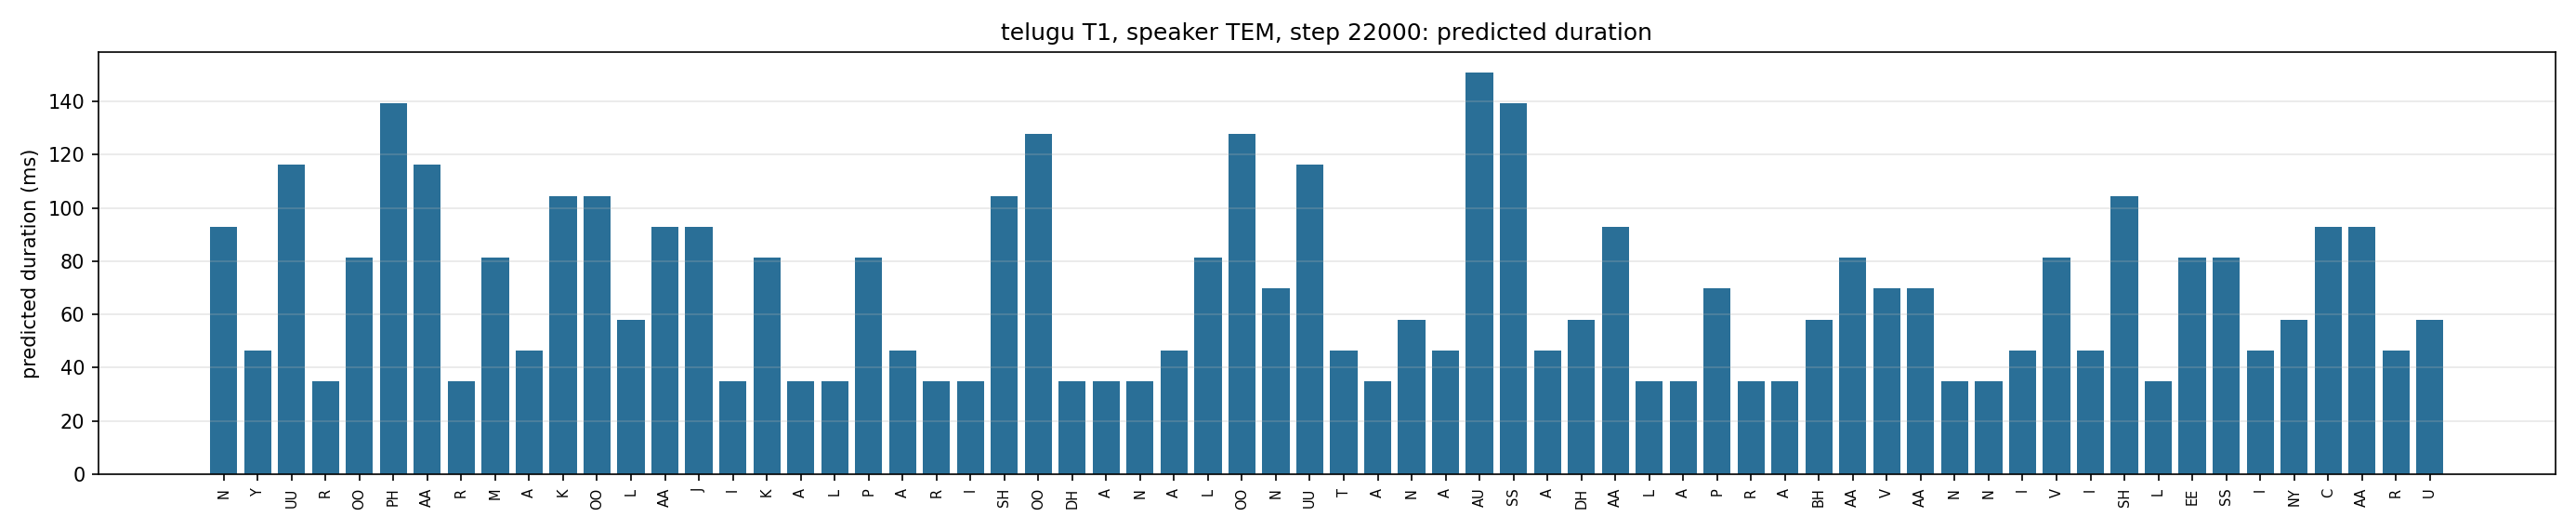

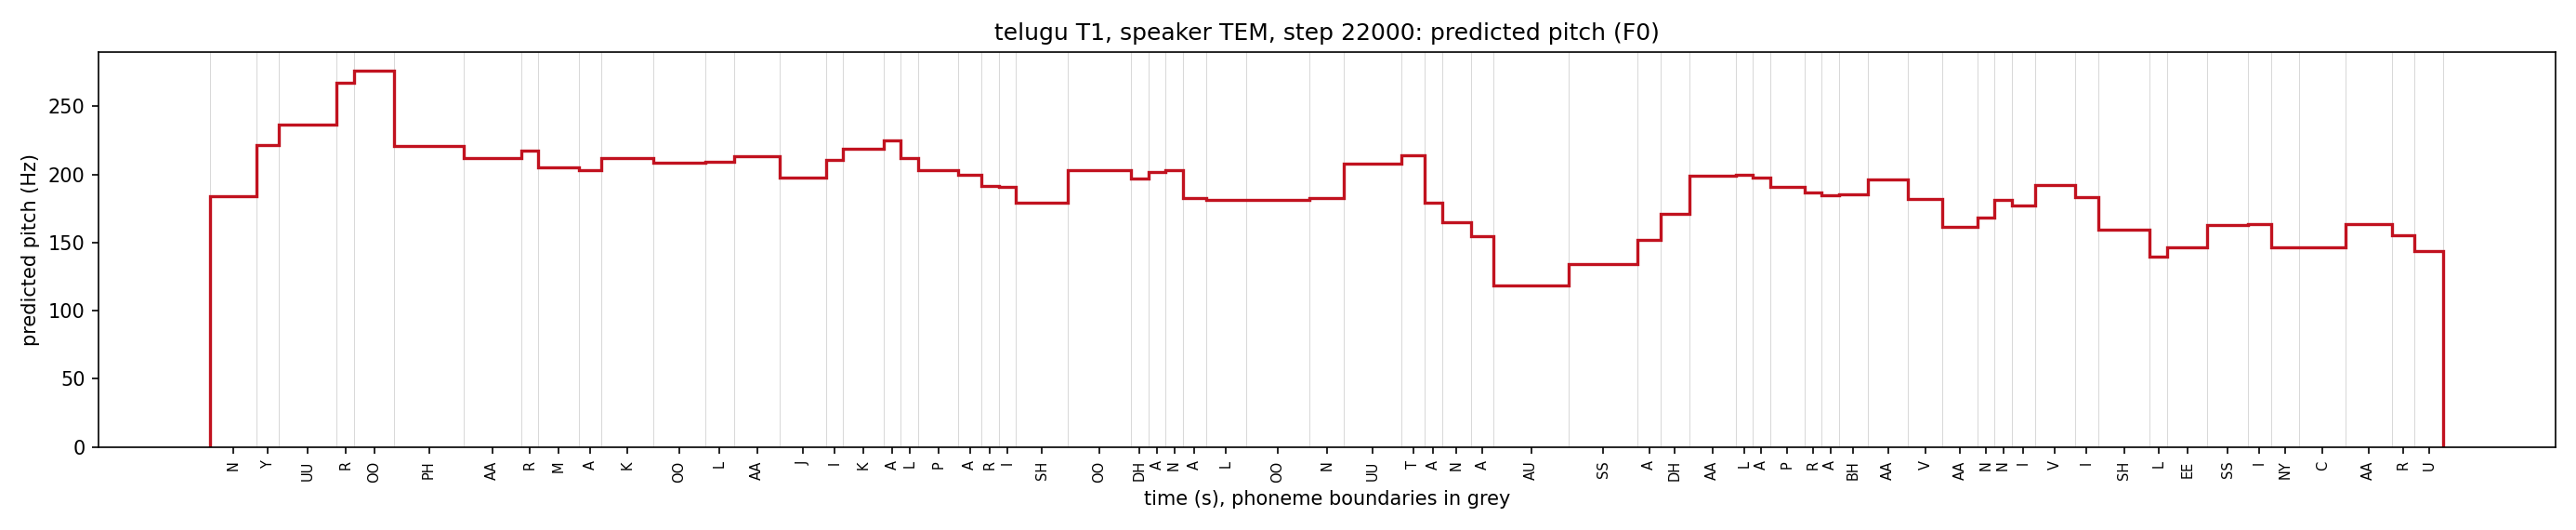

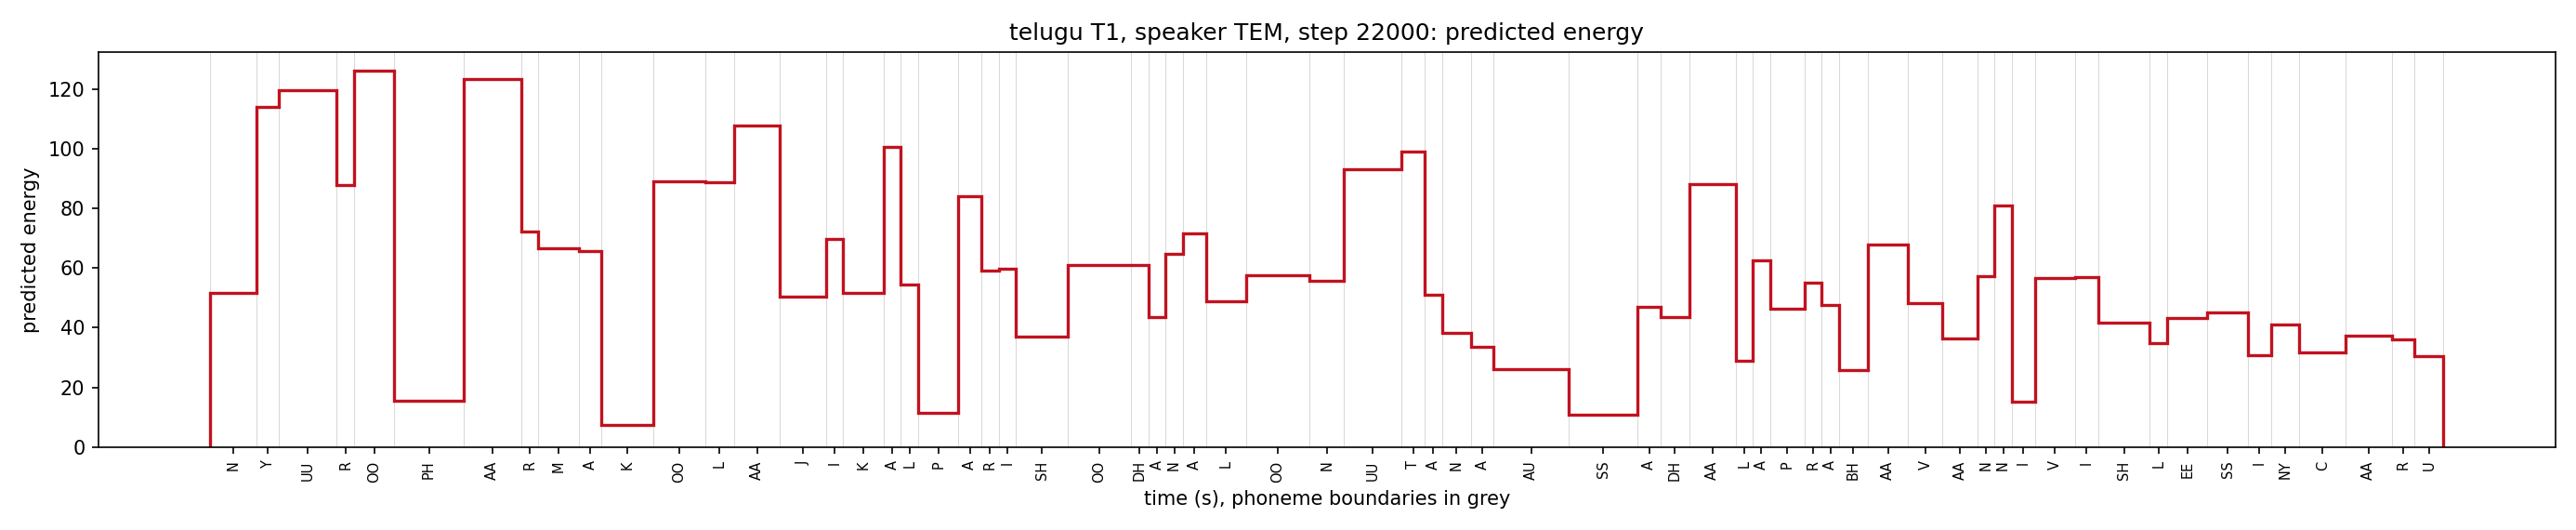

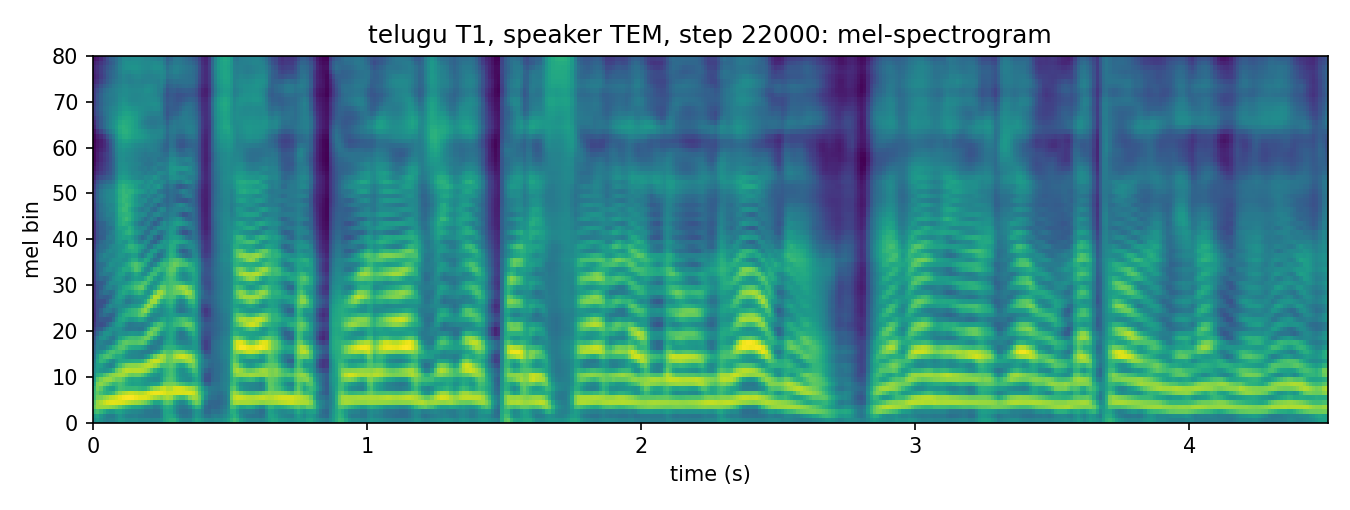

T1
TEXT: న్యూరోఫార్మకోలాజికల్ పరిశోధనలో నూతన ఔషధాల ప్రభావాన్ని విశ్లేషించారు.
NORMALISED: న్యూరోఫార్మకోలాజికల్ పరిశోధనలో నూతన ఔషధాల ప్రభావాన్ని విశ్లేషించారు.
PHONES: N Y UU R OO PH AA R M A K OO L AA J I K A L P A R I SH OO DH A N A L OO N UU T A N A AU SS A DH AA L A P R A BH AA V AA N N I V I SH L EE SS I NY C AA R U

T2a
TEXT: తాడుపై అతని పట్టు చాలా బలంగా ఉంది.
NORMALISED: తాడుపై అతని పట్టు చాలా బలంగా ఉంది.
PHONES: T AA DD U P AI A T A N I P A TT TT U C AA L AA B A L A NG G AA U N D I

T2b
TEXT: ఆమె పట్టుచీరను ధరించి వేడుకకు వచ్చింది.
NORMALISED: ఆమె పట్టుచీరను ధరించి వేడుకకు వచ్చింది.
PHONES: AA M E P A TT TT U C II R A N U DH A R I NY C I V EE DD U K A K U V A C C I N D I

T3
TEXT: పులి అడవిలో నిశ్శబ్దంగా నడిచింది.
NORMALISED: పులి అడవిలో నిశ్శబ్దంగా నడిచింది.
PHONES: P U L I A DD A V I L OO N I SH SH A B D A NG G AA N A DD I C I N D I

T4
TEXT: ఈ సమావేశం 2026 నవంబర్ 12వ తేదీ ఉదయం 10:45 గంటలకు ప్రారంభమవుతుంది, సమయానికి సిద్ధంగా ఉంచండి.
NORMALISED: ఈ సమావేశం రెండు వేల ఇరవై ఆరు నవం

In [5]:
# Show the duration / pitch / energy / mel plots for one version and sentence
from IPython.display import Image, display
RUN = "step_22000_TEM"     # a folder name printed by the cell above
SENTENCE = "T1"
base = f"{D}/Results/Telugu_test/{RUN}"
for kind in ["duration", "pitch", "energy"]:
    display(Image(f"{base}/variance_adaptor_plots/{kind}/{SENTENCE}.png"))
display(Image(f"{base}/mel_plots/{SENTENCE}.png"))
print(open(f"{base}/phoneme_sequences.txt", encoding="utf-8").read()[:1500])

In [6]:
STEP, SPEAKER = 22000, "TEM"
os.chdir("/content/FastSpeech2")
!python inference.py --lang telugu --dataset Telugu --restore_step {STEP} --speaker {SPEAKER} --sentences test_sentences_telugu.json --out {D}/Results/Telugu 2>&1 | tail -8
!ls {D}/Results/Telugu {D}/Results/Telugu/test_generated_audios {D}/Results/Telugu/variance_adaptor_plots

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
Removing weight norm...
T1: 66 phones, 4.50 s of audio
T2a: 31 phones, 2.02 s of audio
T2b: 37 phones, 2.08 s of audio
T3: 31 phones, 1.83 s of audio
T4: 120 phones, 7.00 s of audio
/content/drive/MyDrive/tts_project/Results/Telugu:
mel_plots	       test_generated_audios   variance_data
phoneme_sequences.txt  variance_adaptor_plots

/content/drive/MyDrive/tts_project/Results/Telugu/test_generated_audios:
T1.wav	T2a.wav  T2b.wav  T3.wav  T4.wav

/content/drive/MyDrive/tts_project/Results/Telugu/variance_adaptor_plots:
duration  energy  pitch


In [7]:
from google.colab import drive
drive.mount('/content/drive')
import os
D = "/content/drive/MyDrive/tts_project"
for n in ["textgrids.tar", "preprocessed_Svarah.tar", "textgrids_telugu.tar", "preprocessed_Telugu.tar"]:
    p = f"{D}/{n}"
    print(f"{n:26s}", f"{os.path.getsize(p)/1e6:.2f} MB" if os.path.exists(p) else "missing")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
textgrids.tar              32.20 MB
preprocessed_Svarah.tar    597.91 MB
textgrids_telugu.tar       30.00 MB
preprocessed_Telugu.tar    464.61 MB


In [8]:
STEP, SPEAKER = 22000, "TEM"
os.chdir("/content/FastSpeech2")
!python inference.py --lang telugu --dataset Telugu --restore_step {STEP} --speaker {SPEAKER} --sentences test_sentences_telugu.json --out {D}/Results/Telugu 2>&1 | tail -8
!ls {D}/Results/Telugu {D}/Results/Telugu/test_generated_audios {D}/Results/Telugu/variance_adaptor_plots

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
Removing weight norm...
T1: 66 phones, 4.50 s of audio
T2a: 31 phones, 2.02 s of audio
T2b: 37 phones, 2.08 s of audio
T3: 31 phones, 1.83 s of audio
T4: 120 phones, 7.00 s of audio
/content/drive/MyDrive/tts_project/Results/Telugu:
mel_plots	       test_generated_audios   variance_data
phoneme_sequences.txt  variance_adaptor_plots

/content/drive/MyDrive/tts_project/Results/Telugu/test_generated_audios:
T1.wav	T2a.wav  T2b.wav  T3.wav  T4.wav

/content/drive/MyDrive/tts_project/Results/Telugu/variance_adaptor_plots:
duration  energy  pitch


In [9]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
OUT = f"{D}/Results/Telugu"; os.makedirs(OUT, exist_ok=True)
NAMES = ["Total", "Mel", "Mel PostNet", "Pitch", "Energy", "Duration"]
def parse(path):
    rows = []
    if not os.path.exists(path): return np.array(rows)
    for line in open(path):
        m = re.search(r"Step\s+(\d+)", line)
        vals = [re.search(rf"(?<![A-Za-z]){n} Loss:\s*([0-9.eE+-]+)", line) for n in NAMES]
        if m and all(vals): rows.append([int(m.group(1))] + [float(v.group(1)) for v in vals])
    return np.array(rows)
def plot(rows, title, fname, smooth=0):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    for i, n in enumerate(NAMES):
        y = rows[:, 1 + i]
        if smooth and len(y) > smooth: y = np.convolve(y, np.ones(smooth) / smooth, mode="valid"); x = rows[smooth - 1:, 0]
        else: x = rows[:, 0]
        (ax[0] if n == "Total" else ax[1]).plot(x, y, label=n)
    ax[0].set_title(title + " (total)"); ax[1].set_title(title + " (components)")
    for a in ax: a.set_xlabel("step"); a.set_ylabel("loss"); a.legend(); a.grid(alpha=.3)
    plt.tight_layout(); plt.savefig(f"{OUT}/{fname}", dpi=150); plt.close(); print("saved", fname, len(rows), "points")
LOG = f"{D}/output/log/Telugu"
plot(parse(f"{LOG}/train/log.txt"), "Telugu training loss", "training_loss.png", smooth=5)
plot(parse(f"{LOG}/val/log.txt"), "Telugu validation loss", "validation_loss.png")

saved training_loss.png 230 points
saved validation_loss.png 22 points
